In [1]:
import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)
print("Kernel is working!")

Python version: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
Python location: c:\Users\Aditi Guddeti\AppData\Local\Python\pythoncore-3.14-64\python.exe
Kernel is working!


In [2]:
import pandas as pd
import sklearn
import matplotlib
import seaborn as sns

print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)

print("\nAll libraries imported successfully!")

Pandas: 3.0.6
Scikit-learn: 1.9.1
Matplotlib: 3.11.2
Seaborn: 0.13.2

All libraries imported successfully!


In [3]:
import os

print(os.listdir("."))

['Reviews.csv', 'sentiment_analysis.ipynb']


In [4]:
import pandas as pd

df = pd.read_csv("Reviews.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Number of rows and columns: (568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nRating distribution:")
print(df["Score"].value_counts().sort_index())

Column names:
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']

Missing values in each column:
Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

Rating distribution:
Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64


In [6]:
# Keep only the required columns
df = df[["Score", "Text"]].copy()

# Remove duplicate reviews and missing values
df = df.dropna()
df = df.drop_duplicates(subset=["Score", "Text"])

# Remove neutral reviews (3 stars)
df = df[df["Score"] != 3].copy()

# Create sentiment labels: 1 = Positive, 0 = Negative
df["Sentiment"] = (df["Score"] >= 4).astype(int)

print("Preprocessing completed!")
print("\nDataset shape:", df.shape)
print("\nSentiment distribution:")
print(df["Sentiment"].value_counts())

df.head()

Preprocessing completed!

Dataset shape: (363903, 3)

Sentiment distribution:
Sentiment
1    306819
0     57084
Name: count, dtype: int64


,Score,Text,Sentiment
0,5,I have bought several of the Vitality canned d...,1
1,1,Product arrived labeled as Jumbo Salted Peanut...,0
2,4,This is a confection that has been around a fe...,1
3,2,If you are looking for the secret ingredient i...,0
4,5,Great taffy at a great price. There was a wid...,1


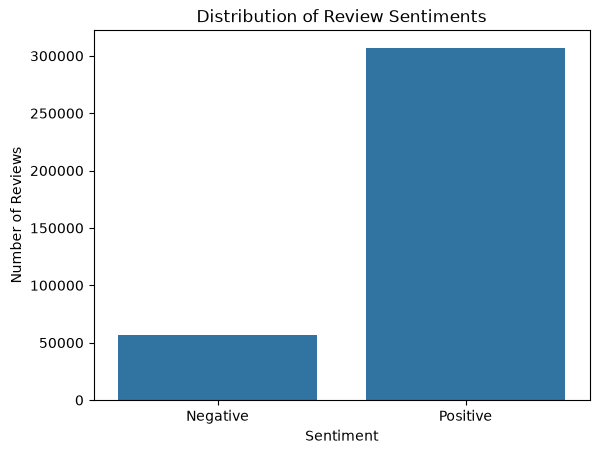

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Sentiment")

plt.xticks([0, 1], ["Negative", "Positive"])
plt.title("Distribution of Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [8]:
from sklearn.model_selection import train_test_split

X = df["Text"]
y = df["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("Data splitting completed!")

Training reviews: 291122
Testing reviews: 72781
Data splitting completed!


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training matrix shape: (291122, 20000)
Testing matrix shape: (72781, 20000)


In [10]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [11]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

Model Accuracy: 93.43 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.68      0.77     11417
    Positive       0.94      0.98      0.96     61364

    accuracy                           0.93     72781
   macro avg       0.91      0.83      0.86     72781
weighted avg       0.93      0.93      0.93     72781



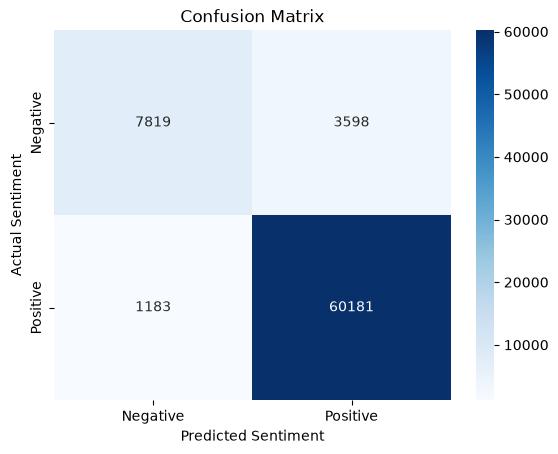

In [12]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix")
plt.show()

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Create an optimized TF-IDF representation
tfidf_optimized = TfidfVectorizer(
    stop_words="english",
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_opt = tfidf_optimized.fit_transform(X_train)
X_test_opt = tfidf_optimized.transform(X_test)

# Train the updated model
model_optimized = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_optimized.fit(X_train_opt, y_train)

# Evaluate the updated model
y_pred_opt = model_optimized.predict(X_test_opt)

from sklearn.metrics import accuracy_score

print("Original Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Optimized Accuracy:", round(accuracy_score(y_test, y_pred_opt) * 100, 2), "%")

Original Accuracy: 93.43 %
Optimized Accuracy: 93.47 %


In [14]:
reviews = [
    "This product tastes amazing and I love it.",
    "Terrible quality, I will never buy this again.",
    "The product is okay but nothing special."
]

predictions = model_optimized.predict(
    tfidf_optimized.transform(reviews)
)

for review, prediction in zip(reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 40)

Review: This product tastes amazing and I love it.
Predicted Sentiment: Positive
----------------------------------------
Review: Terrible quality, I will never buy this again.
Predicted Sentiment: Negative
----------------------------------------
Review: The product is okay but nothing special.
Predicted Sentiment: Negative
----------------------------------------


# Result Analysis and Conclusion

## Result Analysis
- Dataset: Amazon Fine Food Reviews from Kaggle.
- Preprocessing: Removed missing values, duplicate reviews, and neutral 3-star reviews.
- Feature Extraction: TF-IDF was used to convert text into numerical features.
- Machine Learning Algorithm: Logistic Regression.
- Original Model Accuracy: 93.43%.
- Optimized Model Accuracy: 93.47%.
- The optimized model showed a small improvement of 0.04 percentage points.
- The model successfully predicted positive and negative sentiment for sample product reviews.

## Conclusion
The project demonstrates how Natural Language Processing and Machine Learning can be used to classify product reviews as positive or negative. TF-IDF and Logistic Regression produced promising results on the test dataset. The model can be further improved by addressing class imbalance and testing additional algorithms.